# KQC QualityFactor — six λ/4 test resonators on one feedline (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' resonator Q test chip, `chips/quality_factor.py` (class `QualityFactor`,
default parameters; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/quality_factor.py`). Six `QuarterWaveCpwResonator`s
(5374 … 5589 µm, centre widths 5/10/20 µm with gaps 3/6/12 µm) hang below a feedline from launcher WN (PL-1-IN)
to EN (PL-1-OUT) of an SMA8 holder. Each is coupled through an interdigital or gap finger capacitor built into
the element; three start and end galvanically, three through airbridges. No qubits: the measurement is each
resonator's frequency and Q.

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (SMA8 launchers on its edges), Quantcore die frame, device ID "QFACTOR" |
| launchers | SMA8, only pads 8 (PL-1-IN) and 3 (PL-1-OUT), indent 800 µm | same two, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25: every f_r moves up (≈ +5 %) |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`) | **the original wins:** KQC's grid (`with_grid=True`), no PDK band |
| elements, positions, routes | — | kept: KQC's parameters; the resonator x positions follow KQC's own formula from the launcher ports (so they move with the launchers, as KQC's would: the six share a feedline span 160 µm shorter than KQC's, at a 973.3 µm pitch instead of 1000 µm) |
| placement | centred | centred (9 µm off in y, inside the 50 µm tolerance: no shift) |

**Kept:** the feedline path, including KQC's 1000 µm marker safety and the bend up to y = 7794.5 µm (centred
on the longest resonator); the resonator pitch from KQC's formula (1000 µm on KQC's launchers, 973.3 µm on the
deeper ones here); every `QuarterWaveCpwResonator` with its KQC
parameters (length, `max_res_len`, finger count and length, coupler type, `res_a`/`res_b`, beginning/termination
type, `n_ab` airbridges, probe-line stub 120 µm, transmission-line airbridges).

**Structure:** the feedline is seven CPW routes between the resonators' probe-line stubs, as in KQC; only the two
assigned SMA8 pads are drawn, as in KQC.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its two SMA8 launchers, the launchers and the pad rule (they set the resonator pitch), the six λ/4 resonators (this chip has no qubits; each resonator carries its own piece of the feedline), the feedline through them, and then the whole chip (the sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `qualityfactor.v1.ipynb`; both save the same `qualityfactor.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/qualityfactor/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/qualityfactor")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack (resonator frequencies), the frame and pad rule, the airbridge
layers 300/301 and the cheese / 3/0 rules.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die and its launchers, what the line connects, the
line, and then the whole chip. A loss test chip has no qubits, so segment 4 places the resonators instead, and the
coupling and control segments are empty (one sentence each). Each segment is one cell with one picture of the chip so
far (live, KLayout redraws after every cell). A route joins two ports, so the feedline, which runs through the stubs of
the resonators, comes after them. KQC's ground grid (`with_grid`, ≈ 0.8 M holes) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and the SMA8 holder's two launchers (PL-1-IN, PL-1-OUT) |
| 2 | the launchers and the pad rule (they come with the die); their ports set the feedline and the pitch |
| 3 | the readout line: nothing yet (the feedline runs through the resonators' probe-line stubs, Design 5) |
| 4 | no qubits: the six `QuarterWaveCpwResonator`s, each with its 120 µm probe-line stub and coupler |
| 5 | the feedline: seven CPW routes, launcher → stub → … → stub → launcher |
| 6 | the coupling: none besides each resonator's built-in coupler |
| 7 | the control routing: none (no qubits) |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die, its frame and the launchers

10 × 10 mm with the SMA8 holder's pads 8 (PL-1-IN, west) and 3 (PL-1-OUT, east), the chip name "QFACTOR" (device
ID) and `with_grid=True`: KQC's whole-area ground grid, the original's cheese (no PDK band). The Quantcore frame
replaces KQC's ChipFrame.

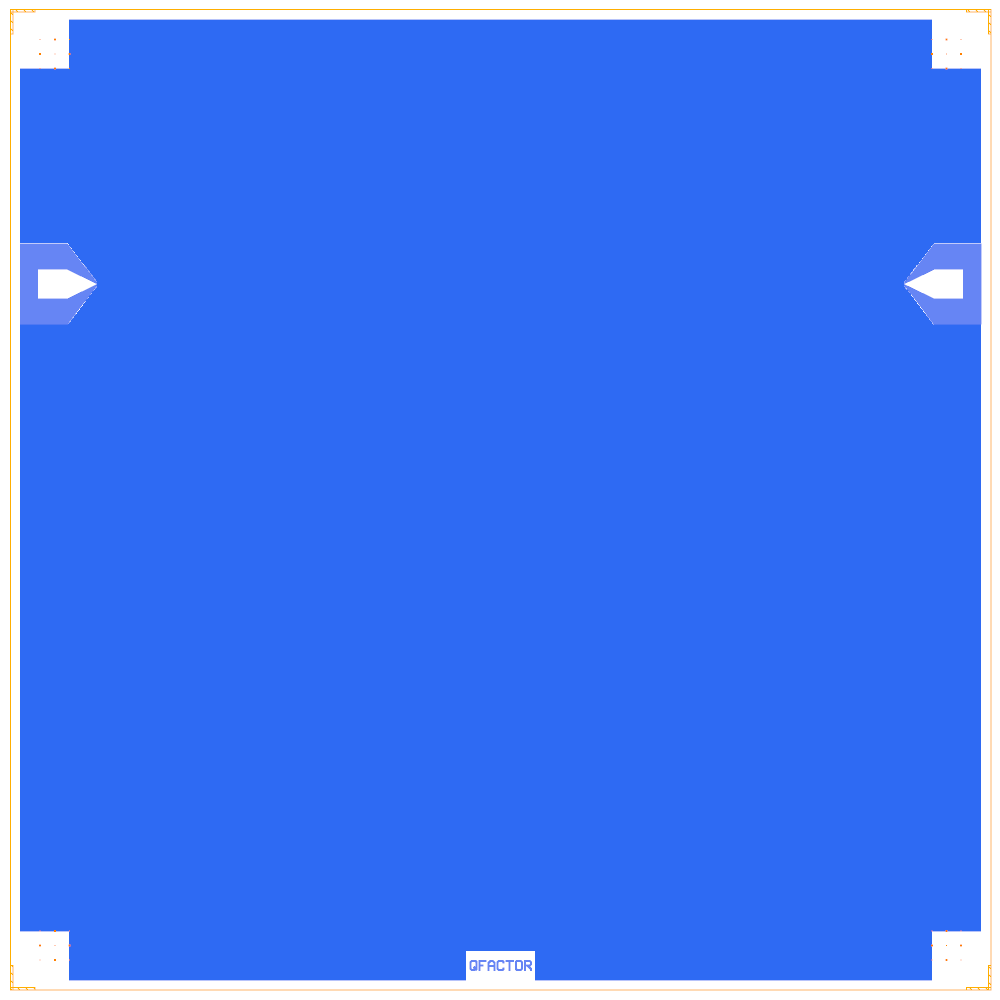

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/qualityfactor/1_die.png')

In [5]:
d = Designer("qualityfactor", box=(0, 0, 10000, 10000),
             launchers={"type": "SMA8", "assign": {8: "PL-1-IN", 3: "PL-1-OUT"}},
             chip={"name_chip": "QFACTOR", "with_grid": True}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the "
                 "pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

SMA8 launchers get `launcher_indent` = 100 + 300 + 300 + 180 = **880 µm** (KQC: 800): outer etch edge
`frame.pad_edge` (100 µm) from the die edge. KQC positions this chip's feedline and resonators from the launcher
refpoints, and so does the rebuild (`x_in`, `x_out` come from the ports here). The six resonators share the span
between the feedline corners, so the 80 µm deeper launchers shorten the pitch from 1000 to 973.3 µm (R0 and R5
sit 67 µm further in than in KQC).

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on PL-1-IN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.PL-1-OUT | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

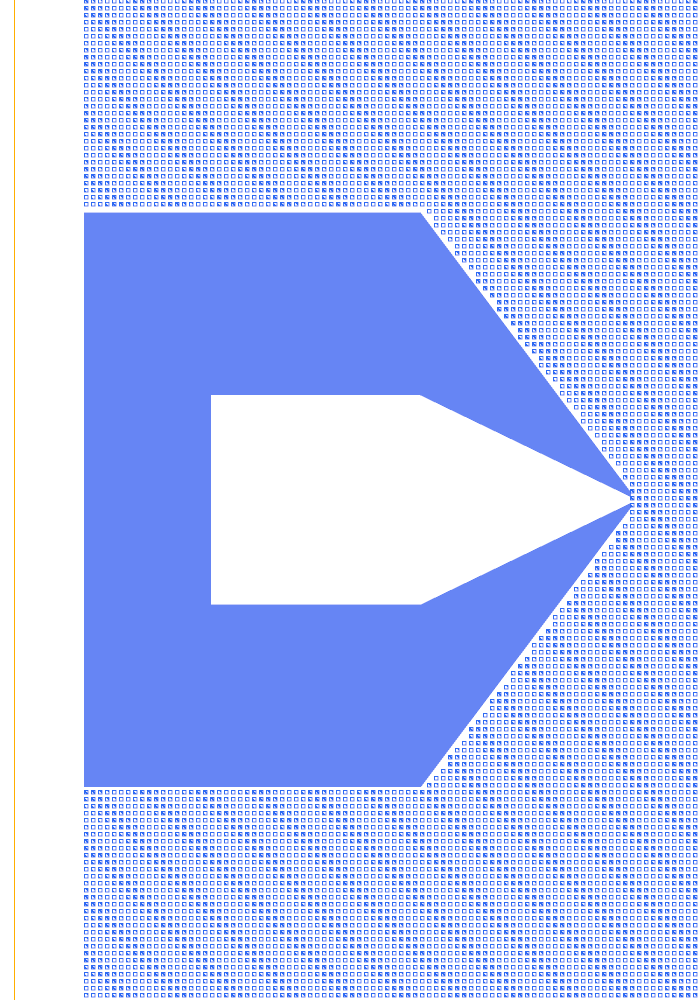

In [6]:
display(Markdown(pads_md(d)))
x_in, y_in = port_xy(d, "chip.PL-1-IN")
x_out, _ = port_xy(d, "chip.PL-1-OUT")
snap(d, STEPS / "2_launcher.png", box=(-20, y_in - 400, x_in + 100, y_in + 400), size=(700, 1000), width=300);

## Design 3 · Readout: the feedline comes after the resonators

Each `QuarterWaveCpwResonator` carries its own 120 µm piece of the feedline (its probe-line stub, ports `a` and `b`),
so the feedline is drawn in Design 5, from stub to stub, once the resonators are there. Nothing to place here.

## Design 4 · No qubits: the six λ/4 resonators

Six KQC `QuarterWaveCpwResonator`s, each a complete element: a 120 µm probe-line stub (ports `a`, `b`), the
coupling capacitor (`type_coupler` interdigital or gap, `n_fingers`, `l_fingers`) and the meandered λ/4 below it
(`resonator_length`, folded within `max_res_len`), with KQC's beginning / termination (`res_beg`, `res_term`:
galvanic or airbridge) and `n_ab` airbridges along it. They share the span between KQC's feedline
corners equally (KQC's formula: a 1000 µm pitch on KQC's launchers, 973.3 µm here), at the feedline height `y_top` that centres the longest resonator on the chip.

The first picture is the chip so far, the second zooms on R0's coupler (no rebuild: the same build).

<QuarterWaveCpwResonator R0 ports=['a', 'b', 'resonator_b']>


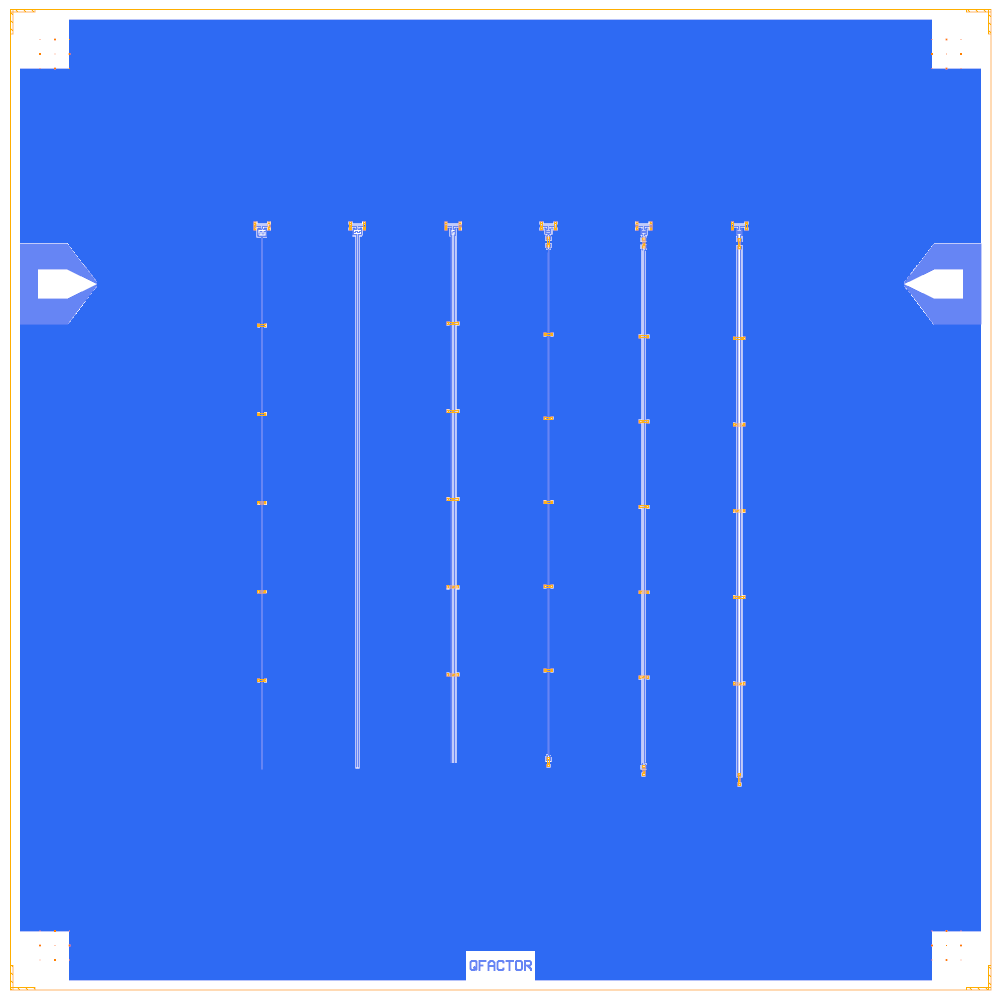

**On the chip so far:** 0 pads · 0 qubits · 6 other components · 0 routes · 0 declared couplings. **This step added** 6 component(s) `R0`, `R1`, `R2`, `R3`, `R4`, `R5`.

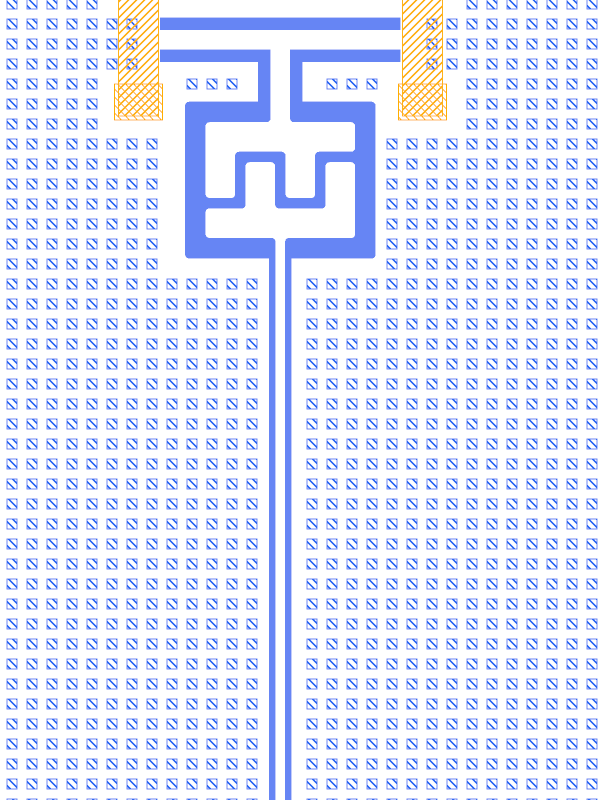

In [7]:
res_lengths = [5434, 5429, 5374, 5412, 5493, 5589]
n_fingers = [4, 4, 2, 4, 4, 4]
l_fingers = [23.1, 9.9, 14.1, 10, 21, 28]
coupler = ["interdigital", "interdigital", "interdigital", "gap", "gap", "gap"]
n_ab = [5, 0, 5, 5, 5, 5]
term = ["galvanic", "galvanic", "galvanic", "airbridge", "airbridge", "airbridge"]
res_a, res_b = [5, 10, 20, 5, 10, 20], [3, 6, 12, 3, 6, 12]

r, safety, bend = 100, 1000, 100                 # KQC: turn radius, marker_safety, feedline_bend_distance
y_top = (10000 + max(res_lengths)) / 2           # feedline height: the longest resonator is centred on the chip
x0, x1 = x_in + r + bend + safety, x_out - r - bend - safety
with d.batch():
    for i in range(6):
        d.add(f"R{i}", "QuarterWaveCpwResonator", at=(x0 + (i + 0.5) * (x1 - x0) / 6, y_top), probeline_length=120.0,
              resonator_length=res_lengths[i], max_res_len=max(res_lengths), res_beg=term[i], res_term=term[i],
              n_ab=n_ab[i], n_fingers=n_fingers[i], l_fingers=l_fingers[i], type_coupler=coupler[i],
              res_a=res_a[i], res_b=res_b[i], tl_airbridges=True)
print(d["R0"])
layout_step(d, STEPS / "s4_resonators.png", **CHIP)
x, y = port_xy(d, "R0.a")
snap(d, STEPS / "s4_r0.png", box=(x - 80, y - 380, x + 220, y + 20), size=(600, 800), width=300);

## Design 5 · Readout: the feedline through the six stubs

The feedline in seven CPW routes: PL-1-IN → up at KQC's marker-safety distance to `y_top` → R0's stub, stub to
stub, R5 → down → PL-1-OUT. The corner positions come from the launcher ports.

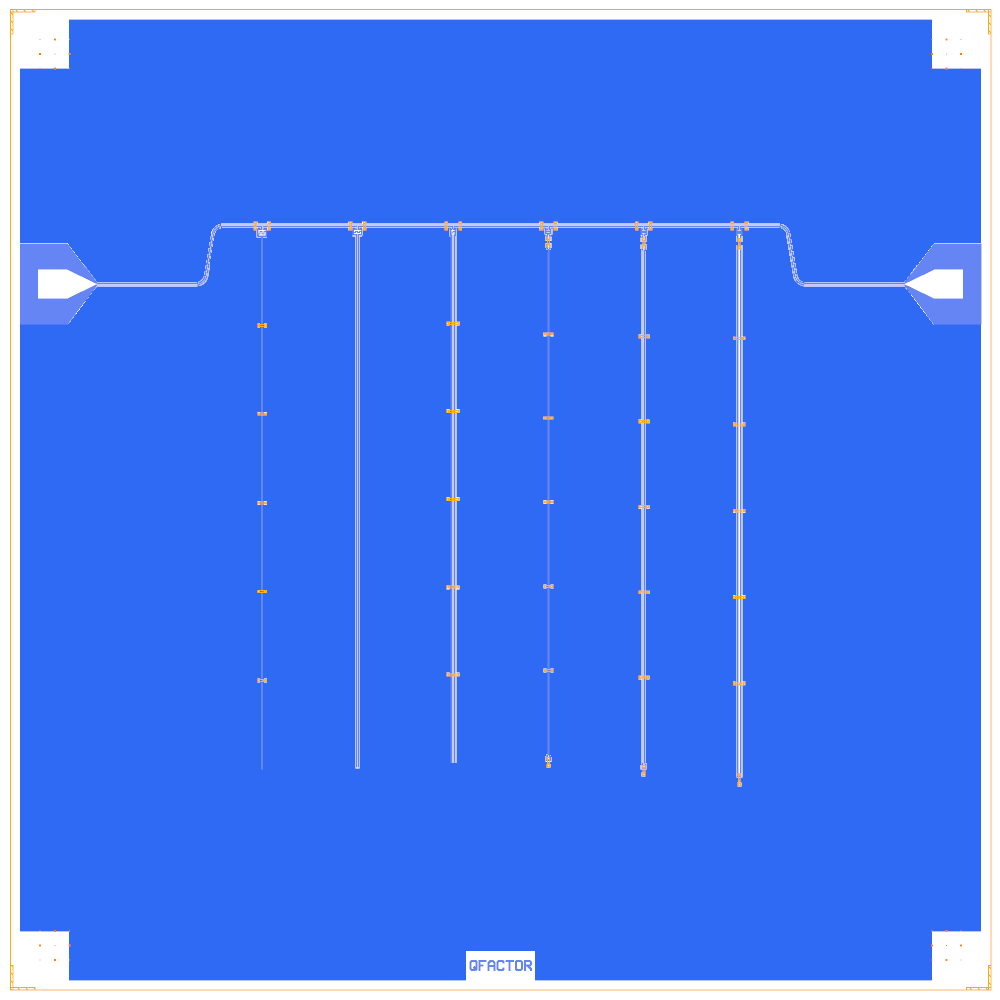

**On the chip so far:** 0 pads · 0 qubits · 6 other components · 7 routes · 0 declared couplings. **This step added** 7 route(s) `FL0`, `FL1`, `FL2`, `FL3`, `FL4`, `FL5`, `FL6`.

{'FL0': 2072.0, 'FL1': 853.3, 'FL2': 853.3, 'FL3': 853.3, 'FL4': 853.3, 'FL5': 853.3, 'FL6': 2072.0}


In [8]:
with d.batch():
    d.route("FL0", "chip.PL-1-IN", "R0.a", nodes=[(x_in + r + safety, y_in), (x0, y_top)])
    for i in range(1, 6):
        d.route(f"FL{i}", f"R{i - 1}.b", f"R{i}.a")
    d.route("FL6", "R5.b", "chip.PL-1-OUT", nodes=[(x1, y_top), (x_out - r - safety, y_in)])
layout_step(d, STEPS / "s5_feedline.png", **CHIP)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

## Design 6 · Coupling: only the built-in couplers

Each resonator couples to the feedline through the finger or gap capacitor inside its own cell (Design 4); nothing
couples the resonators to each other on purpose (973 µm apart), so there is nothing to add here.

## Design 7 · Routing: no control lines

No qubits, so no flux, drive or charge lines.

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups, centring, save.** One sim group per resonator (200 µm margin; eigenmode and Q3D). `center_in_die`
finds the content 9 µm off in y, inside its 50 µm tolerance, so nothing moves; then `qualityfactor.json` is
saved with `save_design`, which compares it with the file it replaces (the previous run's): the segments
above built the chip in the v1's order, so it should say *same design* (byte for byte).

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/qualityfactor.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer qualityfactor: 6 instances, 7 routes, live=False> → examples\designs\kqc\qualityfactor.json


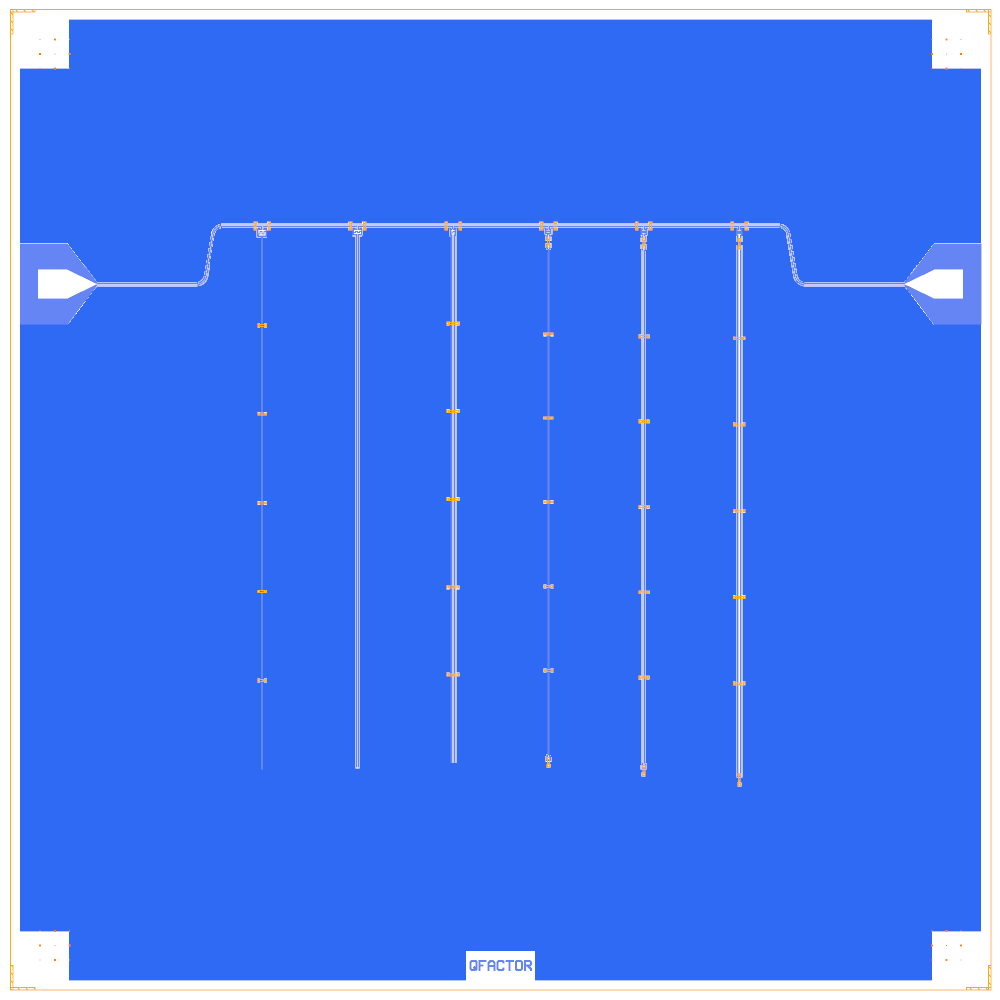

**On the chip so far:** 0 pads · 0 qubits · 6 other components · 7 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/qualityfactor/4_routes.png')

In [9]:
for i in range(6):
    d.sim_group(f"R{i}", [f"R{i}"], margin_um=200, analyses=["eigenmode_epr", "q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "qualityfactor.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "4_routes.png", **CHIP)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** no errors and six `dangling_port` warnings, the resonators' unused `resonator_b` ends; no junctions, so no `pdk_rn` / `pdk_fq`; the launchers follow the pad rule, so no `pad_edge`.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

Each `QuarterWaveCpwResonator` is one element with a probe-line node (ports `a`, `b` are one conductor), a λ/4
resonator node and the finger-capacitor coupling between them; the CPW routes join the probe-line nodes into one
feedline between the two 50 Ω launchers.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**R0's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("R0."))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Six linear resonator modes: frequency and external κ through the two 50 Ω launchers (no junctions, so no
anharmonicity and nothing for QuTiP beyond the harmonic levels). The loaded Q_ext = f_r / κ is what this chip
measures (together with the internal Q, which a LOM does not predict). From the v1 run: R5 5.627 … R2 5.838 GHz, Q_ext ≈ 3800 (R0) to ≈ 86 000 (R5); R0 and R4 only 3.5 MHz apart.

In [ ]:
res = simulate_lom(lb, d.design, max_modes=2)
display(Markdown(modes_md(res)))
display(Markdown("| mode | f_r (GHz) | κ (MHz) | Q_ext = f_r / κ |\n|---|---|---|---|\n" + "\n".join(
    f"| {m.label} | {m.f_GHz:.4f} | {m.kappa_MHz:.3g} | {m.f_GHz * 1e3 / m.kappa_MHz:,.0f} |"
    for m in res.modes if m.kappa_MHz)))

## LOM 2 · The LOM in a plot

The same result as a picture: (a) the six resonator modes (QuCat; squares are resonators), (b) the dispersive-shift
panel stays empty: no qubits, no χ.

In [ ]:
plot_lom({"chip": res}, STEPS / "lom.png", title="qualityfactor: LOM")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The coupling capacitor sets Q_ext. Lengthen R0's interdigital fingers from 23.1 to 40 µm: the coupling
capacitance grows, κ of R0 rises (Q_ext falls, roughly with the square of the capacitance) and f_r drops
slightly; the other five resonators do not change. The change is made on a copy (`design_copy`), so
`qualityfactor.json` keeps KQC's 23.1 µm.

In [ ]:
def modes_delta_md(r0, r1):                      # before/after of every normal mode (QuCat)
    m0, m1 = {m.label: m for m in r0.modes}, {m.label: m for m in r1.modes}
    rows = ["| mode | f before (GHz) | f after (GHz) | Δf (MHz) | κ before (MHz) | κ after (MHz) |",
            "|---|---|---|---|---|---|"]
    for k in m0:
        if k in m1:
            a, b = m0[k], m1[k]
            rows.append(f"| {k} | {a.f_GHz:.4f} | {b.f_GHz:.4f} | {1e3 * (b.f_GHz - a.f_GHz):+.1f} | "
                        f"{a.kappa_MHz:.3g} | {b.kappa_MHz:.3g} |")
    return "\n".join(rows)


d2 = design_copy(DESIGN)
d2["R0"].set(l_fingers=40)
res2 = simulate_lom(d2.lom(), d2.design, max_modes=2)
display(Markdown("**R0 coupler fingers: 23.1 → 40 µm**\n\n" + modes_delta_md(res, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/kqc/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one **eigenmode** job per resonator (cut out with a 200 µm margin): the two feedline routes leaving the box
end in 50 Ω lumped ports, so the solve gives f_r and the external Q, which is what this chip measures. (The
groups also list `q3d_cmatrix`, but in a C-matrix the shorted λ/4 is part of ground, so that job would only have
the feedline net; it is not exported here.)

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/kqc/fem/: solved results are kept here
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")   # one eigenmode job per resonator
display(Markdown(jobs_md(jobs_eig)))

## Simulate 2 · Component simulation: none here

The component step of the plugin is a Q3D C-matrix per group. A shorted λ/4 joins the ground plane at its far end, so
in a C-matrix it is part of ground: the job would hold the feedline only (Simulate 1). The resonators' frequencies and
κ come from the eigenmode (Simulate 3) and the driven run (Simulate 4).

## Simulate 3 · Eigenmode simulation

Each resonator's box in HFSS eigenmode: the two feedline routes leaving it end in 50 Ω, so the resonator mode's Q gives
its κ into the line (Q_ext, what this chip measures, plus the box's other losses).

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the feedline through R0's box: the resonator is a notch, which is how this chip is
measured. The library cannot hand the solved eigenmode **mesh** itself to a driven setup (no such option yet), so
`driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the eigenmode job's mesh seeds, the
adaptive-mesh frequency at the eigenmode's mode nearest R0 (the LOM's f before the eigenmode is solved) and a fast
sweep from 0.4 GHz below to 0.2 GHz above it.

In [ ]:
lom_r = {m.label: m for m in res.modes}          # the LOM's resonator modes (LOM 1)

f_drv = lom_r["R0"].f_GHz   # the LOM's R0 frequency
jobs_drv = driven_from_eigenmode(DESIGN, "R0", jobs_eig["R0"][0], keep_eig["R0"], f_guess=f_drv)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["R0"]:
    display(Markdown(driven_md(keep_drv["R0"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q (no junction: every p_J is 0), with the LOM's six resonator frequencies as dashed lines. The tables below list the
modes.

In [ ]:
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom={k: m.f_GHz for k, m in lom_r.items()})
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

Each LOM resonator against the eigenmode of its own box: `match_modes` picks the solved mode (Q > 100) nearest the
LOM's f. κ = f/Q of the 50 Ω-terminated box and Q_ext = f/κ = Q; the driven run adds R0's notch fit.

In [ ]:
fem_r = {g: match_modes(keep_eig.get(g), {g: lom_r[g].f_GHz}).get(g) for g in keep_eig}
rows = []
for g, e in fem_r.items():
    m = lom_r[g]
    rows.append(f"| `{g}` | {m.f_GHz:.4f} | {m.kappa_MHz:.3g} | {m.f_GHz * 1e3 / m.kappa_MHz:,.0f} | "
                + (f"{e['f_GHz']:.4f} | {1e3 * e['f_GHz'] / e['Q']:.3g} | {e['Q']:,.0f} |" if e else "– | – | – |"))
if any(fem_r.values()):
    display(Markdown("| resonator | LOM f (GHz) | LOM κ (MHz) | LOM Q_ext | FEM f (GHz) | FEM κ (MHz) | FEM Q |\n"
                     "|---|---|---|---|---|---|---|\n" + "\n".join(rows)))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would put each resonator's LOM f, κ and Q_ext next "
          "to its eigenmode f, κ and Q.")
if keep_drv["R0"]:
    print("R0, driven notch:", driven_values(keep_drv["R0"], "R0", f_drv))

## Results 3 · FEM against the LOM

The LOM's f and κ of each resonator (LOM 1) next to the eigenmode's, with the difference in %. The LOM's λ/4 is the
drawn length on a CPW formula; the FEM adds the bends, the coupler's real geometry and the airbridges' ends, so
expect an offset of a few per cent.

In [ ]:
rows = []
for g, e in fem_r.items():
    if e:
        m = lom_r[g]
        rows += [(f"{g}.f_GHz", m.f_GHz, e["f_GHz"], "eigenmode"),
                 (f"{g}.kappa_MHz", m.kappa_MHz, 1e3 * e["f_GHz"] / e["Q"], "eigenmode, f/Q")]
if keep_drv["R0"]:
    rows += [(k, lom_r["R0"].f_GHz if k.endswith("f_GHz") else lom_r["R0"].kappa_MHz, x, "driven S21 notch")
             for k, x in driven_values(keep_drv["R0"], "R0", f_drv).items()]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts each resonator's LOM f and κ next to the "
          "eigenmode's (and R0's driven notch), with the difference in %.")

## Results 4 · Feedback: one step towards a target

KQC's `QualityFactor` states no frequencies, so this notebook sets one as an exercise: **R0 at 5.675 GHz**, between R5
and R4. On sapphire the LOM puts R0 only 3.5 MHz from R4 (from the v1 run: 5.7146 / 5.7181 GHz, with R0's κ ≈ 1.5 MHz),
so the two would be hard to tell apart in a measurement; at 5.675 GHz R0 sits ≈ 48 MHz above R5 and ≈ 43 MHz below R4.
There is no qubit, so `loop.feedback` (which tunes qubit–readout pairs) does not apply; the feedback is the first-order
rule of a λ/4: f ∝ 1/ℓ, so the new `resonator_length` is ℓ · f / f_target (≈ 5434 → 5472 µm here, still inside the
cell's `max_res_len` of 5589 µm). When an eigenmode is kept, the LOM is first scaled by FEM / LOM of R0 (`SCALE`), so
the step aims at the FEM value. The target goes on a copy (`target_copy` → `build/qualityfactor_target.json`); the
revisions are copies of it.

In [ ]:
F_T, F_TOL = 5.675, 0.001                        # the exercise target for R0 and its tolerance (GHz)
DESIGN_T = target_copy(DESIGN, {"R0": {"f_GHz": F_T}})
f_lom = lom_r["R0"].f_GHz
f_fem = (fem_r.get("R0") or {}).get("f_GHz")
SCALE = f_fem / f_lom if f_fem else 1.0          # FEM / LOM at the drawn length (1: the LOM alone)
L0 = float(d.data["instances"]["R0"]["params"]["resonator_length"])
L1 = rule_step(L0, SCALE * f_lom, F_T, -1.0)
display(Markdown(f"**R0:** now {SCALE * f_lom:.4f} GHz ({'FEM' if f_fem else 'LOM'}), target {F_T} ± {F_TOL} GHz → "
                 f"resonator_length {L0:.1f} → **{L1:.1f} µm** (f ∝ 1/ℓ)"))

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the length, its LOM runs (× `SCALE`), and the next step uses the
exponent of the last two points (a secant), until R0 is within 1 MHz or `MAX_ITER` steps are made; the length stays
within the cell's `max_res_len`. With `RUN_FEM = True` each revision's R0 eigenmode is exported to `build/jobs/rev<k>/`
and solved (minutes each), and the loop closes on the FEM's R0.

In [ ]:
def f_r0_of(k, it):
    """Revision it: R0 k µm long; its frequency on the LOM (× SCALE), or from its own eigenmode with RUN_FEM."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["R0"].set(resonator_length=k)
    path = d2.save(Path("build") / f"qualityfactor_rev{it}.json")
    r = {m.label: m for m in simulate_lom(d2.lom(), d2.design, max_modes=2).modes}
    if RUN_FEM:
        job = export_sims(path, ["R0"], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        keep = fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["R0"]
        e = match_modes(keep, {"R0": r["R0"].f_GHz}).get("R0")
        if e:
            return e["f_GHz"], path
    return SCALE * r["R0"].f_GHz, path


MAX_LEN = float(d.data["instances"]["R0"]["params"]["max_res_len"])
history = rule_iterate(f_r0_of, "R0.f_GHz", "R0.resonator_length", L0, F_T, F_TOL, -1.0, max_iter=MAX_ITER,
                       start=(SCALE * f_lom, DESIGN_T), fem=bool(RUN_FEM), bounds=(0.5 * L0, MAX_LEN))
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `qualityfactor.json` is the whole design: `qcc build examples/designs/kqc/qualityfactor.json`
rebuilds `build/qualityfactor.oas` + sidecar.

**The fab mask.** `export_fab` writes the PDK fab layers: base etch 1/0 with the cheese (source `build`: KQC's
grid), the filled 3/0 keep-out (route + 10 µm, component + 24 µm, plus every grid hole), the airbridges on 300/0 (pads) and 301/0 (bridges) — KQC's resonator and
feedline bridges — and the frame (100/0, 1000/0, 1001/0). Corner rounding is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/qualityfactor.json` writes the complete file.

**Simulation export options.** No cheese in simulation exports; airbridges are dropped unless `airbridges=True`
— here that matters, since R3–R5 are airbridge-terminated and every line carries bridges. `setup.geometry`
reports what was left out.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "R3", "eigenmode_epr", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Fab 2 · Snapshots

Full chip; the couplers of R0 (interdigital, galvanic ends) and R3 (gap coupler, airbridge-terminated); the die
frame's south-west corner; R0's coupler in the **fab view** (the mask from Fab 1: 1/0 with KQC's grid holes,
the 3/0 keep-out, the airbridge layers); and KQC's own `QualityFactor` built stand-alone. (The layout snapshots
show KQC's ground grid, as one tone at full-chip scale, and draw the chip boundary 100/0 as an outline; the fab
view shows the grid holes on 1/0 and on 3/0.)

In [ ]:
show_snapshot(d, OUT / "qualityfactor.png", box=(-100, -100, 10100, 10100))   # chip only
for i in (0, 3):
    x, y = port_xy(d, f"R{i}.a")
    show_snapshot(d, OUT / f"qualityfactor_coupler_r{i}.png", box=(x + 10, y - 180, x + 130, y + 20), width=360)
show_snapshot(d, OUT / "qualityfactor_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
x, y = port_xy(d, "R0.a")
snap_file(Path("build") / "qualityfactor_fab.oas", OUT / "qualityfactor_fab_r0.png", box=(x - 80, y - 280, x + 220, y + 20),
          size=(1200, 1200), width=420);

In [ ]:
from kqcircuits.chips.quality_factor import QualityFactor
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_qualityfactor")
top.insert(pya.DCellInstArray(QualityFactor.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "qualityfactor_kqc_original.oas"))
snap_file(Path("build") / "qualityfactor_kqc_original.oas", OUT / "qualityfactor_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

## Summary

| | |
|---|---|
| **matches the source** | the six `QuarterWaveCpwResonator`s with KQC's parameters, the feedline path and pitch (from the launcher refpoints, as KQC), the two SMA8 pads, the airbridges; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame; launchers 80 µm further in (outer etch 100 µm, `frame.pad_edge`), so the resonator pitch is 973.3 µm instead of 1000 µm (R0 and R5 67 µm further in); sapphire (f_r ≈ 5 % higher than on silicon) |
| **PDK design warnings** | none |
| **FEM** | 6 eigenmode jobs and R0's driven job exported (`build/jobs/qualityfactor_R*`), not solved here |
| layout | built in eight segments (die and launchers, the launcher check, the feedline deferred to the resonators' stubs, the six resonators, the feedline; no coupling and no control lines; the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (R0 5.675 GHz): the λ/4 rule f ∝ 1/ℓ on R0's `resonator_length`, iterated with a secant (LOM × FEM/LOM scale; eigenmode per revision with `RUN_FEM`) |
| open | the FEM jobs (eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |